# 01 — Introdução, Protocolo e Carregamento da Base BETA

> **Adaptação de:** `SSVEP/intro.ipynb`, `SSVEP/load_single_avi.ipynb` e `SSVEP/load_multi_avi_exemplo.ipynb` ([bneurd/tutoriais](https://github.com/bneurd/tutoriais)) para o **Dataset BETA** (Liu et al., 2020).

## Comparativo entre o Dataset Original do Tutorial (AVI) e a Nossa Base (BETA)

| Característica | AVI SSVEP (Tutorial Original) | BETA Dataset (Nossa Adaptação) |
| :--- | :--- | :--- |
| **Participantes** | 4 (*Single-Target*) / 5 (*Multi-Target*) | **70 voluntários** (`S1` a `S10` locais para prototipação) |
| **Eletrodos Gravados** | 1 canal (`Oz`) | **64 canais** (padrão 10-20; foco nos 9 parieto-occipitais) |
| **Taxa de Amostragem** | 512 Hz | **250 Hz** |
| **Alvos / Frequências** | 7 frequências (6.0 a 10.0 Hz) | **40 alvos** (8.0 a 15.8 Hz, passo de 0.2 Hz, 4 fases) |
| **Estrutura por Sujeito** | 1–2 sessões longas (16s a 30s) | **4 blocos × 40 alvos = 160 ensaios** de 3.0s (`S1–S15`) |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.bneurd_beta import load_beta_subject, CHANNEL_PRESETS, PROCESSED_DATA_DIR

print("Diretório raiz do projeto:", PROJECT_ROOT)
print("Presets espaciais configurados:", CHANNEL_PRESETS)

Diretório raiz do projeto: C:\Users\victor\Documents\GitHub\OPT098
Presets espaciais configurados: {'all': None, '9ch': [47, 53, 54, 55, 56, 57, 60, 61, 62], '5ch': [55, 54, 56, 61, 60], '3ch': [60, 61, 62], 'oz': [61]}


### 1. Inspeção de todos os 10 participantes locais (`S1.mat` a `S10.mat`)
Assim como em `load_single_avi.ipynb` e `load_multi_avi_exemplo.ipynb`, inspecionamos a divisão dos dados, os rótulos de frequência e os metadados fisiológicos de cada participante.

In [2]:
subjects_meta = []
for sub_id in range(1, 11):
    X_sub, y_freqs_sub, y_cls_sub, blocks_sub, meta = load_beta_subject(sub_id, channels="all", window="full")
    subjects_meta.append(meta)
    print(
        f"{meta['subject_id']:>3s} | shape={X_sub.shape} | "
        f"idade={meta['age']:4.1f} | gênero={meta['gender']:6s} | "
        f"BCI_Q={meta['bci_quotient']:5.1f} | Wide_SNR={meta['wide_snr_db']:6.2f} dB"
    )

print("\nSequência ordenada das 40 frequências alvo (Hz):")
print(subjects_meta[0]["freqs"])

 S1 | shape=(160, 64, 750) | idade=26.5 | gênero=female | BCI_Q=108.4 | Wide_SNR=-12.48 dB
 S2 | shape=(160, 64, 750) | idade=17.4 | gênero=male   | BCI_Q= 92.1 | Wide_SNR=-15.00 dB
 S3 | shape=(160, 64, 750) | idade=27.8 | gênero=female | BCI_Q=111.2 | Wide_SNR=-12.06 dB
 S4 | shape=(160, 64, 750) | idade=35.5 | gênero=male   | BCI_Q= 87.1 | Wide_SNR=-15.77 dB
 S5 | shape=(160, 64, 750) | idade=26.4 | gênero=male   | BCI_Q= 80.6 | Wide_SNR=-16.77 dB
 S6 | shape=(160, 64, 750) | idade=23.0 | gênero=female | BCI_Q= 87.3 | Wide_SNR=-15.74 dB
 S7 | shape=(160, 64, 750) | idade=22.5 | gênero=male   | BCI_Q= 83.0 | Wide_SNR=-16.40 dB
 S8 | shape=(160, 64, 750) | idade=28.0 | gênero=male   | BCI_Q= 96.5 | Wide_SNR=-14.33 dB
 S9 | shape=(160, 64, 750) | idade=21.3 | gênero=female | BCI_Q=102.9 | Wide_SNR=-13.33 dB
S10 | shape=(160, 64, 750) | idade=20.1 | gênero=female | BCI_Q= 98.4 | Wide_SNR=-14.03 dB

Sequência ordenada das 40 frequências alvo (Hz):
[ 8.   8.2  8.4  8.6  8.8  9.   9.2  9.4

### 2. Padronização e Salvamento em `.npy`
No tutorial original (`load_single_avi.ipynb`), os ensaios são padronizados e salvos em arquivos `.npy` (`data.npy` e `labels.npy`) para consumo nos notebooks seguintes. Aqui salvamos o participante `S1` padronizado no formato `(160, 64, 750)` (4 blocos × 40 alvos = 160 tentativas):

In [3]:
X_s1, y_freqs_s1, y_cls_s1, blocks_s1, meta_s1 = load_beta_subject(1, channels="all", window="full")

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
np.save(PROCESSED_DATA_DIR / "beta_s1_data.npy", X_s1)
np.save(PROCESSED_DATA_DIR / "beta_s1_labels_freq.npy", y_freqs_s1)
np.save(PROCESSED_DATA_DIR / "beta_s1_blocks.npy", blocks_s1)

print("Arquivos salvos em data/processed/:")
print(" - beta_s1_data.npy       :", X_s1.shape, X_s1.dtype)
print(" - beta_s1_labels_freq.npy:", y_freqs_s1.shape, y_freqs_s1[:10])
print(" - 9 canais occipitais    :", [meta_s1["all_ch_names"][i] for i in CHANNEL_PRESETS["9ch"]])

Arquivos salvos em data/processed/:
 - beta_s1_data.npy       : (160, 64, 750) float32
 - beta_s1_labels_freq.npy: (160,) [8.  8.2 8.4 8.6 8.8 9.  9.2 9.4 9.6 9.8]
 - 9 canais occipitais    : ['PZ', 'PO5', 'PO3', 'POZ', 'PO4', 'PO6', 'O1', 'OZ', 'O2']


### 3. Visualização Exploratória Inicial (Perfil dos Participantes e Traçado Bruto no Canal `OZ`)

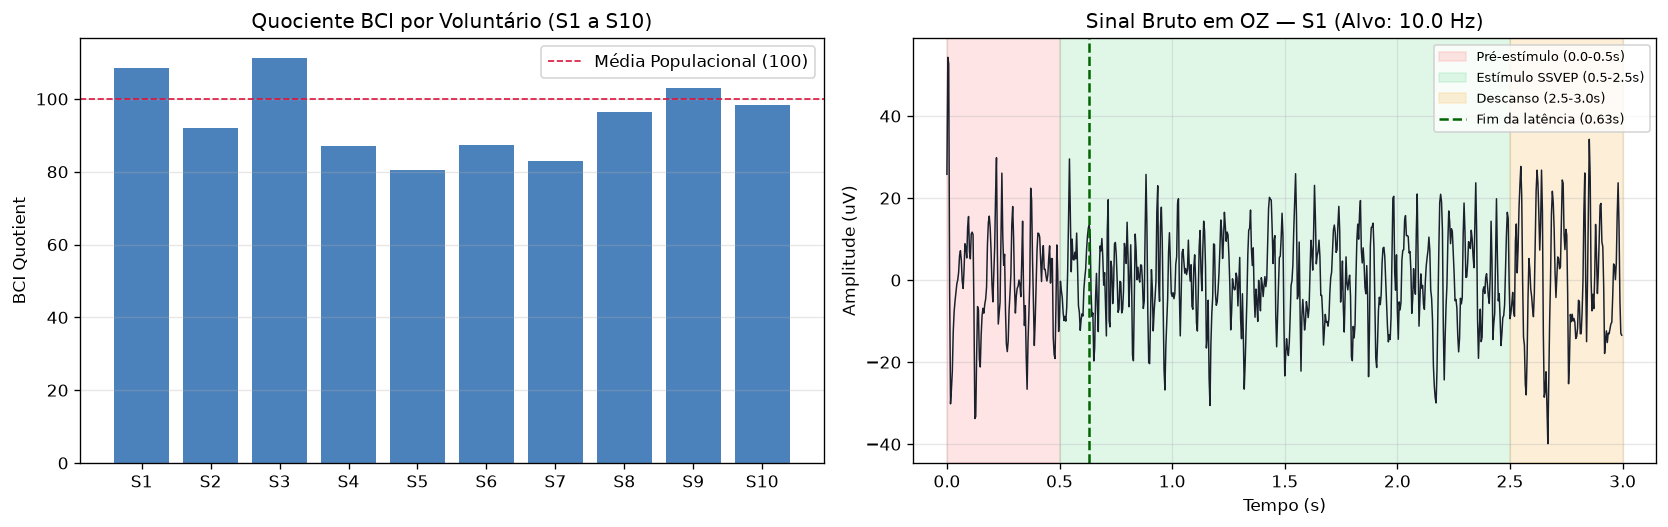

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sub_names = [m["subject_id"] for m in subjects_meta]
bci_q = [m["bci_quotient"] for m in subjects_meta]
snrs = [m["wide_snr_db"] for m in subjects_meta]

axes[0].bar(sub_names, bci_q, color="#2b6cb0", alpha=0.85)
axes[0].axhline(100, color="crimson", linestyle="--", linewidth=1, label="Média Populacional (100)")
axes[0].set_title("Quociente BCI por Voluntário (S1 a S10)")
axes[0].set_ylabel("BCI Quotient")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

oz_idx = CHANNEL_PRESETS["oz"][0]
times = np.arange(X_s1.shape[-1]) / meta_s1["sfreq"]
trial_10hz = np.where(np.isclose(y_freqs_s1, 10.0))[0][0]

axes[1].plot(times, X_s1[trial_10hz, oz_idx, :], color="#1a202c", linewidth=0.9)
axes[1].axvspan(0.0, 0.5, color="#feb2b2", alpha=0.35, label="Pré-estímulo (0.0-0.5s)")
axes[1].axvspan(0.5, 2.5, color="#9ae6b4", alpha=0.30, label="Estímulo SSVEP (0.5-2.5s)")
axes[1].axvspan(2.5, 3.0, color="#fbd38d", alpha=0.35, label="Descanso (2.5-3.0s)")
axes[1].axvline(0.63, color="darkgreen", linestyle="--", label="Fim da latência (0.63s)")
axes[1].set_title(f"Sinal Bruto em OZ — S1 (Alvo: {y_freqs_s1[trial_10hz]:.1f} Hz)")
axes[1].set_xlabel("Tempo (s)")
axes[1].set_ylabel("Amplitude (uV)")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()